In [1]:
import importlib
import subprocess
import sys
import types
import random
import json

def import_fix(package: str, pip_name: str = None) -> types.ModuleType:
    try:
        return importlib.import_module(package)
    except ModuleNotFoundError as e:
        if e.name != package.split(".")[0]:
            raise

        subprocess.check_call([
            sys.executable, "-m", "pip", "install",
            pip_name or package
        ])

        importlib.invalidate_caches()
        return importlib.import_module(package)

datasets  = import_fix("datasets")
# pillow   = import_fix("pillow")
numpy     = import_fix("numpy")
plt       = import_fix("matplotlib.pyplot")
pywidgets = import_fix("ipywidgets")

try:
    import torch, torchvision
except Exception:
    # for cuda local, windows compatibile
    %pip install torch==2.11.0 torchvision==0.26.0 --index-url https://download.pytorch.org/whl/cu128
finally:
    import torch, torchvision

from typing import List, Tuple, Dict, Optional

from datasets import load_dataset
from functools import cache
from torch.utils.data import DataLoader, Dataset, TensorDataset
from matplotlib.figure import Figure
# %matplotlib inline

torch.backends.cudnn.benchmark = True

In [2]:
!nvidia-smi -L

GPU 0: NVIDIA GeForce RTX 2060 (UUID: GPU-ba23c874-bcac-9e5c-3f94-8f3e9fcaf22b)


In [3]:
MY_SEED: int = 1010101

torch.manual_seed(MY_SEED)
random.seed(MY_SEED)

@cache
def get_dataset():
    return load_dataset("uoft-cs/cifar10")

dataset = get_dataset()

train = dataset["train"]
test = dataset["test"]

image = train[0]["img"]
label = train[0]["label"]

(32, 32)
Labels: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


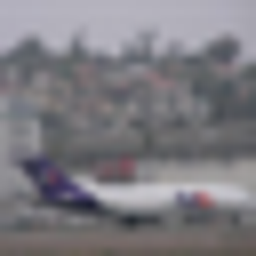

Image class: airplane


In [4]:
from IPython.display import display # for linters and global compability

label_names: List[str] = train.features["label"].names
print(image.size) # no error - good
print(f"Labels: {[ l for l in label_names ]}")

display(image.resize((256, 256)))
print(f"Image class: {label_names[label]}")


In [5]:
from torch import nn
device = str(torch.accelerator.current_accelerator().type) if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [6]:
train_set: torch.Tensor = train.with_format("torch")[:]
test_set: torch.Tensor  = test.with_format("torch")[:]

print(type(train_set), train_set.keys())
print(type(train_set["img"]), train_set["img"][:1].shape, train_set["img"].dtype)

train_set_images: torch.Tensor = train_set["img"].float() / 255.0
test_set_images: torch.Tensor  = test_set["img"].float() / 255.0

train_set_labels: torch.Tensor = train_set["label"]
test_set_labels: torch.Tensor  = test_set["label"]

train_set_images = train_set_images.to(device)
test_set_images  = test_set_images.to(device)
train_set_labels = train_set_labels.to(device)
test_set_labels  = test_set_labels.to(device)

print(train_set_images.dtype)

<class 'dict'> dict_keys(['img', 'label'])
<class 'torch.Tensor'> torch.Size([1, 3, 32, 32]) torch.uint8
torch.float32


In [7]:
@torch.no_grad()
def augment_images(images: torch.Tensor) -> torch.Tensor:
    # 4 poixel padding, 32x32 sample, random horizontal flip
    max_shift: int = 4
    images_number, _, height, width = images.shape

    padded_images: torch.Tensor  = nn.functional.pad(
        images,
        (max_shift, max_shift, max_shift, max_shift),
    ).to(device)
    shift_y: torch.Tensor = torch.randint(0, 2 * max_shift + 1, (images_number,), device=device)
    shift_x: torch.Tensor = torch.randint(0, 2 * max_shift + 1, (images_number,), device=device)

    shifted: torch.Tensor = torch.empty_like(images)
    # one pass per possible offset (9 x 9 = 81), each takes all images that drew it
    for dy in range(2 * max_shift + 1):
        for dx in range(2 * max_shift + 1):
            chosen: torch.Tensor = (shift_y == dy) & (shift_x == dx)
            shifted[chosen] = padded_images[chosen, :, dy : dy + height, dx : dx + width]
    del padded_images

    flipped: torch.Tensor = torch.rand(images_number, device=device) < 0.5
    shifted[flipped] = shifted[flipped].flip(3)

    return shifted


In [8]:
mean_image: torch.Tensor = train_set_images.mean(0)

def mean_image_substraction(image_subset: torch.Tensor) -> torch.Tensor:
    return image_subset - mean_image

train_set_images = mean_image_substraction(train_set_images)
test_set_images  = mean_image_substraction(test_set_images)

validation_set_images: torch.Tensor = train_set_images[45_000 : ]
validation_set_labels: torch.Tensor = train_set_labels[45_000 : ]

train_set_images: torch.Tensor      = train_set_images[ : 45_000]
train_set_labels: torch.Tensor      = train_set_labels[ : 45_000]

assert validation_set_labels.size(0) == 5_000

validation_dataset: Dataset = TensorDataset(validation_set_images, validation_set_labels)

test_dataset: Dataset = TensorDataset(
    test_set_images,
    test_set_labels
)

In [9]:
from dataclasses import dataclass

@dataclass
class ConvLayerShape:
    in_size: int
    out_size: int
    kernel_size: int
    strides: int
    is_bias: bool

In [10]:
class PlainNetwork(nn.Module):
    def __init__(self, layers_shapes: List[List[ConvLayerShape]]) -> None:
        super().__init__()

        layers: List[nn.Module] = []

        for n_layer_segment in layers_shapes:
            for layer in n_layer_segment:
                layers += [
                    nn.Conv2d(
                        layer.in_size,
                        layer.out_size,
                        layer.kernel_size,
                        stride=layer.strides,
                        padding=layer.kernel_size // 2,
                        bias=layer.is_bias
                    ),
                    nn.BatchNorm2d(layer.out_size), # this is cause of batch notrmalisation mentioned later on
                    nn.ReLU()
                ]

        layers += [
            nn.AdaptiveAvgPool2d(1), # global average pooling
            nn.Flatten(),
            nn.Linear(layers_shapes[-1][-1].out_size, 10) # 10 wayfully-connected layer (well we have 10 classes)
        ]

        self.layers: nn.Sequential = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)


In [11]:
class ResidualBlock(nn.Module):
    def __init__(self, layers: List[ConvLayerShape]) -> None:
        super().__init__()
        components: List[nn.Module] = []
        prev_dimension: int = layers[0].in_size
        post_dimension: int = layers[-1].out_size

        for layer in layers[ : -1]:
            components += [
                nn.Conv2d(
                    layer.in_size,
                    layer.out_size,
                    layer.kernel_size,
                    stride=layer.strides,
                    padding=layer.kernel_size // 2,
                    bias=layer.is_bias
                ),
                nn.BatchNorm2d(layer.out_size), # this is cause of batch notrmalisation mentioned later on
                nn.ReLU()
            ]
        tmp_layer: ConvLayerShape = layers[ -1]
        components += [
            nn.Conv2d(
                tmp_layer.in_size,
                tmp_layer.out_size,
                tmp_layer.kernel_size,
                stride=tmp_layer.strides,
                padding=tmp_layer.kernel_size // 2,
                bias=tmp_layer.is_bias
            ),
            nn.BatchNorm2d(tmp_layer.out_size)
        ]

        self.stride_product: int = 1
        for layer in layers:
            self.stride_product *= layer.strides

        self.components: nn.Sequential = nn.Sequential(*components)
        # self.resizer: nn.Module        = (
        #     nn.Identity()
        #     if prev_dimension == post_dimension and stride_product == 1 else
        #     # nn.Linear(prev_dimension, post_dimension, bias=False)
        #     nn.Conv2d(prev_dimension, post_dimension, 1, stride_product, bias=False)
        # )

        self.padding_extra: int = post_dimension - prev_dimension
        self.padding_left: int  = self.padding_extra // 2
        self.relu: nn.Module    = nn.ReLU()

    def resizer(self, x: torch.Tensor) -> torch.Tensor:
        stride: int = self.stride_product
        # this is weird, but it means:
        # [:] <- pass everything as is
        # [ :: n ] <- pass each nth element ex. 
        # [0, 1, 2, 3, 4, 5, 6, 7][ ::3] -> [0, 3, 6]
        # x shall be (batch size, channels, height, width)
        x = x[:, :, ::stride, ::stride] 

        channels_before: int = self.padding_left
        channels_after: int  = self.padding_extra - channels_before

        # https://docs.pytorch.org/docs/2.15/generated/torch.nn.functional.pad.html
        return nn.functional.pad(
            x,
            (0, 0, 0, 0, channels_before, channels_after),
        )


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.relu(self.components(x) + self.resizer(x))

class ResidualNetwork(nn.Module):
    def __init__(self, layers_shapes: List[List[ConvLayerShape]], skip_connection_by: int = 2) -> None:
        super().__init__()

        layers: List[nn.Module] = []

        flat_segments: List[ConvLayerShape] = []
        for n_layer_segment in layers_shapes:
            flat_segments.extend(n_layer_segment)

        first: ConvLayerShape = flat_segments[0]
        flat_segments         = flat_segments[1 : ]

        if skip_connection_by < 1 or len(flat_segments) % skip_connection_by:
            raise ValueError("The remaining convolutions must form complete residual blocks.")

        layers.extend([
            nn.Conv2d(
                first.in_size,
                first.out_size,
                first.kernel_size,
                stride=first.strides,
                padding=first.kernel_size // 2,
                bias=first.is_bias
            ),
            nn.BatchNorm2d(first.out_size),
            nn.ReLU()
        ])

        for i, layer in enumerate(flat_segments):
            if (i + 1) % skip_connection_by == 0:
                layers += [
                    ResidualBlock(flat_segments[ i + 1 - skip_connection_by : i + 1])
                ]

        layers += [
            nn.AdaptiveAvgPool2d(1), # global average pooling
            nn.Flatten(),
            nn.Linear(layers_shapes[-1][-1].out_size, 10) # 10 wayfully-connected layer (well we have 10 classes)
        ]

        self.layers: nn.Sequential = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)


In [12]:
from copy import deepcopy

article_plain_layers_shapes: List[List[ConvLayerShape]] = [
    [ ConvLayerShape(3, 16, 3, 1, False) ],   # input layer shan't change
    [ ConvLayerShape(16, 16, 3, 1, False) ],  # 1
    [ ConvLayerShape(16, 32, 3, 2, False) ],  # connecting layer;
    [ ConvLayerShape(32, 32, 3, 1, False) ],  # 3
    [ ConvLayerShape(32, 64, 3, 2, False) ],  # connecting layer;
    [ ConvLayerShape(64, 64, 3, 1, False) ],  # 5
]

def layer_builder(article_shapes: List[List[ConvLayerShape]], n: int) -> List[List[ConvLayerShape]]:
    tmp: List[List[ConvLayerShape]] = deepcopy(article_shapes)
    tmp[1] *= 2 * n
    tmp[3] *= 2 * n - 1
    tmp[5] *= 2 * n - 1
    return tmp

In [13]:
plain_3: PlainNetwork = PlainNetwork(layer_builder(article_plain_layers_shapes, 3))
plain_3 = plain_3.to(device)

In [14]:
# returns loss and correct hits totals
def training_loop(
    my_nn: nn.Module,
    dataset: Dataset,
    loss_function: nn.Module,
    optimizer: torch.optim.Optimizer,
    batch_size: int = 128
) -> Tuple[float, int]:
    my_nn.train()
    data_loader: DataLoader = DataLoader(dataset, batch_size, shuffle = True)

    total_loss: torch.Tensor   = torch.zeros((), device=device)
    correct_hits: torch.Tensor = torch.zeros((), dtype=torch.long, device=device)

    for x, y in data_loader:
        almost_prediction: torch.Tensor = my_nn(x)
        loss: torch.Tensor              = loss_function(almost_prediction, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # loss is average loss over all outputs so, sum(y_err) / size(y_err) * size(y_err) = sum(y_Err)
        total_loss   += loss.detach() * y.numel()
        correct_hits += (almost_prediction.argmax(1) == y).sum()

    return (float(total_loss.item()), int(correct_hits.item()))

In [15]:
@torch.no_grad()
def evaluate(my_nn: nn.Module, validation_dataset: Dataset, loss_function: nn.Module) -> Tuple[float, int]:
    my_nn.eval()

    total_loss: torch.Tensor   = torch.zeros((), device=device)
    correct_hits: torch.Tensor = torch.zeros((), dtype=torch.long, device=device)

    for x, y in DataLoader(validation_dataset, 128):
        prediction: torch.Tensor = my_nn(x)
        loss: torch.Tensor       = loss_function(prediction, y)
        total_loss               += loss.detach() * y.numel()
        correct_hits             += (prediction.argmax(1) == y).sum()

    return (float(total_loss.item()), int(correct_hits.item()))

In [16]:
json_path: str         = "progress.json"
json_test_section: str = "test"

def save_training_output(
    training_data: List[Tuple[float, int]], 
    validation_data: List[Tuple[float, int]],
    name: str
) -> None:
    
    try:
        with open(json_path, "r") as progress:
            progress_json = json.load(progress)
    except FileNotFoundError:
        with open(json_path, "x+") as progress:
            json.dump({}, progress)
    
    with open(json_path, "r+") as progress:
        progress_json: Dict = json.load(progress)
        progress_json[name] = {
            "train": training_data,
            "val":   validation_data
        }

        progress.seek(0) # to overwrite 
        json.dump(progress_json, progress, indent=4)
        progress.truncate() # actually not required, but will leave it for good conconcisenessc

# saves loss, total hits, avg loss, accuracy
def save_test_output(
    test_results: Dict[str, Tuple[float, int, float, float]]
) -> None:
    try:
        with open(json_path, "r") as progress:
            progress_json = json.load(progress)
    except FileNotFoundError:
        with open(json_path, "x+") as progress:
            json.dump({}, progress)

    with open(json_path, "r+") as progress:
        progress_json: Dict = json.load(progress)
        if not progress_json.get(json_test_section):
            progress_json[json_test_section] = {}
        progress_json[json_test_section].update(
            test_results
        )

        progress.seek(0)
        json.dump(progress_json, progress, indent=4)
        progress.truncate()
    

def load_training_output() -> Dict:
    progress_json: Dict = {}
    with open(json_path, "r") as progress:
        progress_json = json.load(progress)

    return progress_json

In [17]:
def run_training(my_nn: nn.Module, name: str, epochs: int = 64) -> Tuple[List[Tuple[float, int]], List[Tuple[float, int]]]:
    torch.manual_seed(MY_SEED)
    optimizer = torch.optim.SGD(my_nn.parameters(), lr=0.1, momentum=0.9, weight_decay=0.0001)
    training_data: List[Tuple[float, int]]   = []
    validation_data: List[Tuple[float, int]] = []

    for it in range(epochs):
        if (it + 1) in [32, 48]:
            # couold be also done by: torch.optim.lr_scheduler import LambdaLR
            for group in optimizer.param_groups:
                print(f"[Iteration: {it + 1}] Changing learing rate from {group["lr"]} to {group["lr"] / 10.0}")
                group["lr"] /= 10.0

        augmented_cifar10_dataset: Dataset = TensorDataset(
            augment_images(train_set_images),
            train_set_labels
        )

        training_data.append(
            training_loop(
                my_nn,
                augmented_cifar10_dataset,
                nn.CrossEntropyLoss(),
                optimizer,
                64 if "200" in name else 128 # ugly
            )
        )

        validation_data.append(
            evaluate(
                my_nn,
                validation_dataset,
                nn.CrossEntropyLoss()
            )
        )

        if (it + 1) % 10 == 0:
            print(f"{name}: epoch {it + 1}/{epochs}")

    save_training_output(training_data, validation_data, name)

    return training_data, validation_data

In [18]:
def plot_history(
    training_data_output: List[Tuple[float, int]],
    validation_data_output: List[Tuple[float, int]],
    graph: Optional[Figure] = None,
    *,
    name: Optional[str] = None,
    train_data_size: int = 45_000,
    validation_data_size: int = 5_000,
    color: Optional[str] = None,
) -> Figure:
    if graph is None:
        graph, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
    else:
        # The inline backend can close the figure after a previous plt.show().
        plt.figure(graph)
        ax_loss, ax_acc = graph.axes

    if name is None:
        name = f"Run {len(ax_loss.lines) // 2 + 1}"

    for split, history, size, style in (
        ("train", training_data_output, train_data_size, "-"),
        ("val", validation_data_output, validation_data_size, "--"),
    ):
        epochs = range(1, len(history) + 1)
        losses = [loss / size for loss, _ in history]
        accuracies = [hits / size for _, hits in history]
        label = f"{name} {split}"

        loss_line, = ax_loss.plot(
            epochs, losses, color=color, lw=2, ls=style, label=label,
        )
        color = loss_line.get_color()
        ax_acc.plot(
            epochs, accuracies, color=color, lw=2, ls=style, label=label,
        )

    ax_loss.set(title="Loss", xlabel="Epoch", ylabel="Loss")
    ax_acc.set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy (fraction)", ylim=(0, 1))
    for ax in (ax_loss, ax_acc):
        ax.grid(alpha=0.3)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.legend(frameon=False)

    return graph


In [19]:
# plain_16 = PlainNetwork(layer_builder(article_plain_layers_shapes, 16)).to(device)

# t_plain, v_plain = run_training(plain_16, "plain n = 16", 5)

In [20]:
# res_16 = ResidualNetwork(layer_builder(article_plain_layers_shapes, 16)).to(device)

# t_res, v_res = run_training(res_16, "run n = 16", 5)

In [21]:
# fig = plot_history(t_plain, v_plain, name = "plain n = 16",  color = "blue")
# fig = plot_history(t_res, v_res, name = "res n = 16",  color = "red")
# plt.show()

In [22]:
# no. layers = n * 6 + 2

plain_3   = PlainNetwork(layer_builder(article_plain_layers_shapes, 3)).to(device)
plain_5   = PlainNetwork(layer_builder(article_plain_layers_shapes, 5)).to(device)
plain_7   = PlainNetwork(layer_builder(article_plain_layers_shapes, 7)).to(device)
plain_9   = PlainNetwork(layer_builder(article_plain_layers_shapes, 9)).to(device)
plain_18  = PlainNetwork(layer_builder(article_plain_layers_shapes, 18)).to(device)
plain_200 = PlainNetwork(layer_builder(article_plain_layers_shapes, 200)).to(device)

res_3   = ResidualNetwork(layer_builder(article_plain_layers_shapes, 3)).to(device)
res_5   = ResidualNetwork(layer_builder(article_plain_layers_shapes, 5)).to(device)
res_7   = ResidualNetwork(layer_builder(article_plain_layers_shapes, 7)).to(device)
res_9   = ResidualNetwork(layer_builder(article_plain_layers_shapes, 9)).to(device)
res_18  = ResidualNetwork(layer_builder(article_plain_layers_shapes, 18)).to(device)
res_200 = ResidualNetwork(layer_builder(article_plain_layers_shapes, 200)).to(device)

In [23]:
all_networks: List[Tuple[nn.Module, str]] = [ 
    (plain_3, "plain3"),
    (plain_5, "plain_5"), 
    (plain_7, "plain_7"), 
    (plain_9, "plain_9"), 
    (plain_18, "plain_18"), 
    # (plain_200, "plain_200"), 
    (res_3, "res_3"), 
    (res_5, "res_5"), 
    (res_7, "res_7"), 
    (res_9, "res_9"), 
    (res_18, "res_18"), 
    # (res_200 , "res_200")
]

big_networks: List[Tuple[nn.Module, str]] = [ (plain_200, "plain_200"), (res_200 , "res_200") ]

plain3: epoch 10/64
plain3: epoch 20/64
plain3: epoch 30/64
[Iteration: 32] Changing learing rate from 0.1 to 0.01
plain3: epoch 40/64
[Iteration: 48] Changing learing rate from 0.01 to 0.001
plain3: epoch 50/64
plain3: epoch 60/64
plain_5: epoch 10/64
plain_5: epoch 20/64
plain_5: epoch 30/64
[Iteration: 32] Changing learing rate from 0.1 to 0.01
plain_5: epoch 40/64
[Iteration: 48] Changing learing rate from 0.01 to 0.001
plain_5: epoch 50/64
plain_5: epoch 60/64
plain_7: epoch 10/64
plain_7: epoch 20/64
plain_7: epoch 30/64
[Iteration: 32] Changing learing rate from 0.1 to 0.01
plain_7: epoch 40/64
[Iteration: 48] Changing learing rate from 0.01 to 0.001
plain_7: epoch 50/64
plain_7: epoch 60/64
plain_9: epoch 10/64
plain_9: epoch 20/64
plain_9: epoch 30/64
[Iteration: 32] Changing learing rate from 0.1 to 0.01
plain_9: epoch 40/64
[Iteration: 48] Changing learing rate from 0.01 to 0.001
plain_9: epoch 50/64
plain_9: epoch 60/64
plain_18: epoch 10/64
plain_18: epoch 20/64
plain_18: 

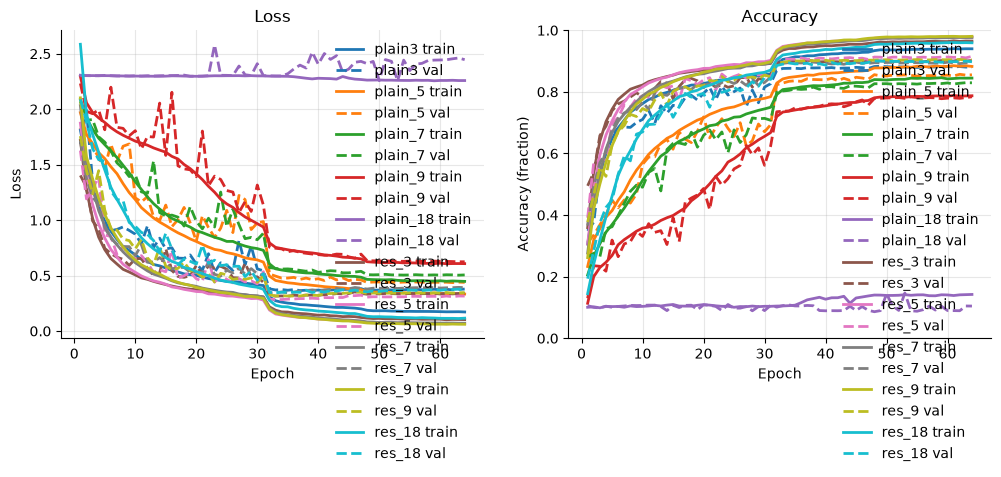

In [24]:
figure = None

for network, name in all_networks:
    training_data, validation_data = run_training(network, name)
    figure = plot_history(training_data, validation_data, figure, name=name)

plt.show()

In [25]:
test_results: Dict[str, Tuple[float, int, float, float]] = {}

for network, name in all_networks:
    test_result: Tuple[float, int] = evaluate(network, test_dataset, nn.CrossEntropyLoss())

    mean_loss: float = test_result[0] / len(test_dataset)
    accuracy: float  = test_result[1] / len(test_dataset)

    test_results[name] = (test_result[0], test_result[1], mean_loss, accuracy)

    save_test_output(test_results)

    print(f"{name}: test loss = {mean_loss:.4f}, accuracy = {accuracy:.2%}")

plain3: test loss = 0.3856, accuracy = 88.18%
plain_5: test loss = 0.4666, accuracy = 84.51%
plain_7: test loss = 0.5368, accuracy = 81.93%
plain_9: test loss = 0.6351, accuracy = 77.98%
plain_18: test loss = 2.4454, accuracy = 10.02%
res_3: test loss = 0.3490, accuracy = 89.87%
res_5: test loss = 0.3510, accuracy = 90.49%
res_7: test loss = 0.3988, accuracy = 89.24%
res_9: test loss = 0.3477, accuracy = 90.13%
res_18: test loss = 0.3754, accuracy = 89.21%
